# Visualisation des données


## Import

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

## 1. Quel produit cumule le plus de vente au total ?

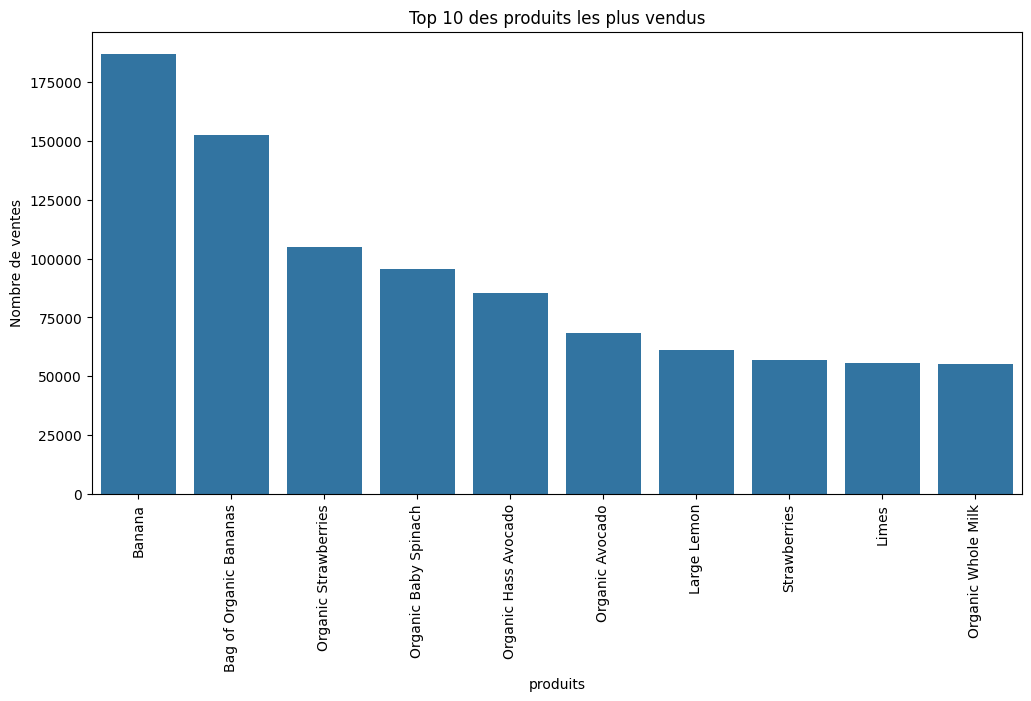

                                            product_name  total_sales
0                                                 Banana       187148
1                                 Bag of Organic Bananas       152420
2                                   Organic Strawberries       104957
3                                   Organic Baby Spinach        95561
4                                   Organic Hass Avocado        85569
...                                                  ...          ...
48875                           Chianti Classico Tuscany            1
48876  Ocean Beach Almond Butter, Coffee, TCHO Cocoa ...            1
48877            Pomegranate Mint Chia Vitality Beverage            1
48878                     Jalapeno Cheddar Sliced Cheese            1
48879                                        Peach Rings            1

[48880 rows x 2 columns]


In [3]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")


vente = df['product_name'].value_counts().reset_index() # reset index ca créé plein de colonnes pour les produits sinon sns kiffe pas
vente.columns = ['product_name', 'total_sales']

vente = vente.sort_values(by='total_sales', ascending=False)
top10 = vente.head(10)

plt.figure(figsize=(12,6))
sns.barplot(x='product_name', y='total_sales', data=top10)
plt.title("Top 10 des produits les plus vendus")
plt.xlabel("produits")
plt.ylabel("Nombre de ventes")
plt.xticks(rotation= 90)
plt.show()
print(vente)

## 2. Quel est l'article le moins/plus vendu parmi chacun des 'department' ?

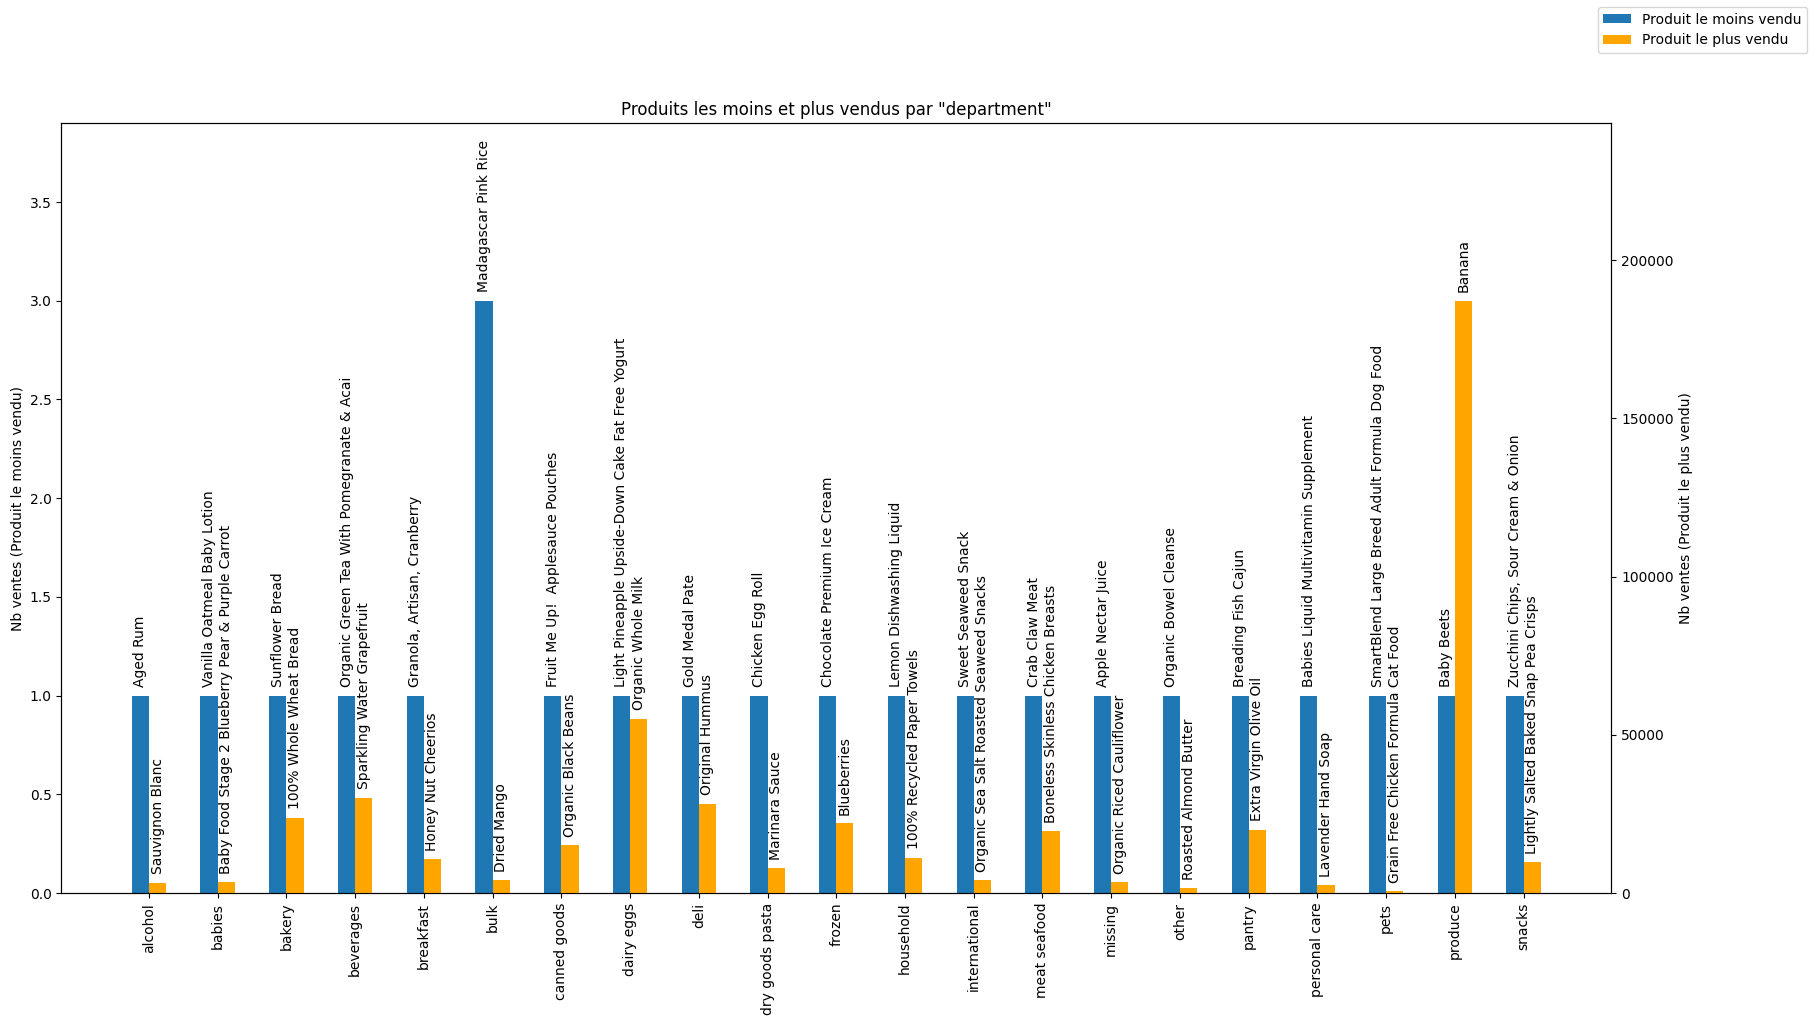

In [4]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")
grouped_df = df.groupby(["department", "product_name"])["product_name"].count().reset_index(name='Nb de vente').sort_values(["Nb de vente"], ascending=False)
grouped_df1 = grouped_df.groupby(["department"]).first()
grouped_df2 = grouped_df.groupby(["department"]).last()

departments = grouped_df1.index.to_list()

most_sells = grouped_df1["product_name"].to_list()
most_nb_sells = grouped_df1["Nb de vente"].to_list()

less_sells = grouped_df2["product_name"].to_list()
less_nb_sells = grouped_df2["Nb de vente"].to_list()

fig, ax1 = plt.subplots(figsize=(20,10)) # crée une figure de taille 20 par 9 pouces et un axe X et Y
ax1.margins(y=0.3) # met des marges à l'axe y pour ne pas que le texte sorte du cadre

w, x = 1, np.arange(len(departments)) * 4 # w est la taille de chaque barre, x est un tableau contenant la position du milieu de chaque barre pour chaque 'department'

bars1 = ax1.bar(x - w/2, less_nb_sells, w, label="Produit le moins vendu") # x - w/2 permet de décaler la barre vers la gauche par rapport à son centre
ax1.set_ylabel("Nb ventes (Produit le moins vendu)")

ax2 = ax1.twinx() # crée un second axe y partageant le même axe x que ax1
ax2.margins(y=0.3) # met des marges à l'axe y pour ne pas que le texte sorte du cadre
bars2 = ax2.bar(x + w/2, most_nb_sells, w, label="Produit le plus vendu", color="orange") # x + w/2 permet de décaler la barre vers la droite par rapport à son centre
ax2.set_ylabel("Nb ventes (Produit le plus vendu)")

ax1.set_xticks(x) # place les petits traits sur l'axe x
ax1.set_xticklabels(departments, rotation=90, fontsize=10) # place le nom des 'deparments' en dessous des petits traits sur l'axe x

# affiche le texte au-dessus des barres
ax1.bar_label(bars1, labels=less_sells, padding=6, rotation=90, fontsize=10)
ax2.bar_label(bars2, labels=most_sells, padding=6, rotation=90, fontsize=10)

plt.title('Produits les moins et plus vendus par "department"')

fig.legend(loc="upper right")

plt.show()

## 3. Quel produit est généralement vendu avec chacun des articles les plus populaires ?

## 4. Quelle est la probabilité qu'un acheteur rachète un produit parmi une catégorie dont il a déjà acheté ?

## 5. Peut-on prédire la date de la prochaine commande d'un client en fonction de la fréquence à laquelle il commande ?

## 6. Est-ce que le jour et l'heure influence le nombre de vente parmi chaque "departement" ?

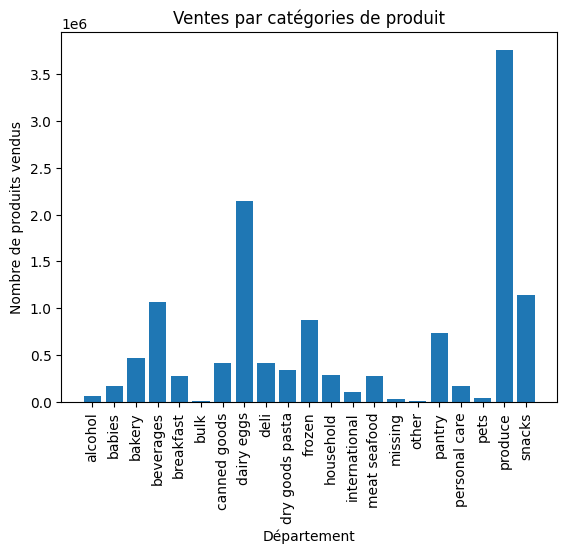

department
alcohol              59803
babies              169192
bakery              464981
beverages          1065640
breakfast           278627
bulk                 13950
canned goods        419516
dairy eggs         2145940
deli                413989
dry goods pasta     339822
frozen              876847
household           288968
international       105258
meat seafood        278916
missing              28445
other                14346
pantry              737589
personal care       175080
pets                 38525
produce            3756335
snacks             1139911
dtype: int64


In [5]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")
df1 = pd.read_csv("datasets-project/datasets/departments.csv")


VenteParDep = df.groupby('department').size() # compte le nombre de de ligne ds chaque département 

plt.bar(VenteParDep.index , VenteParDep.values)
plt.xlabel("Département")
plt.ylabel("Nombre de produits vendus")
plt.title("Ventes par catégories de produit")
plt.xticks(rotation=90)
plt.show()

print(VenteParDep)

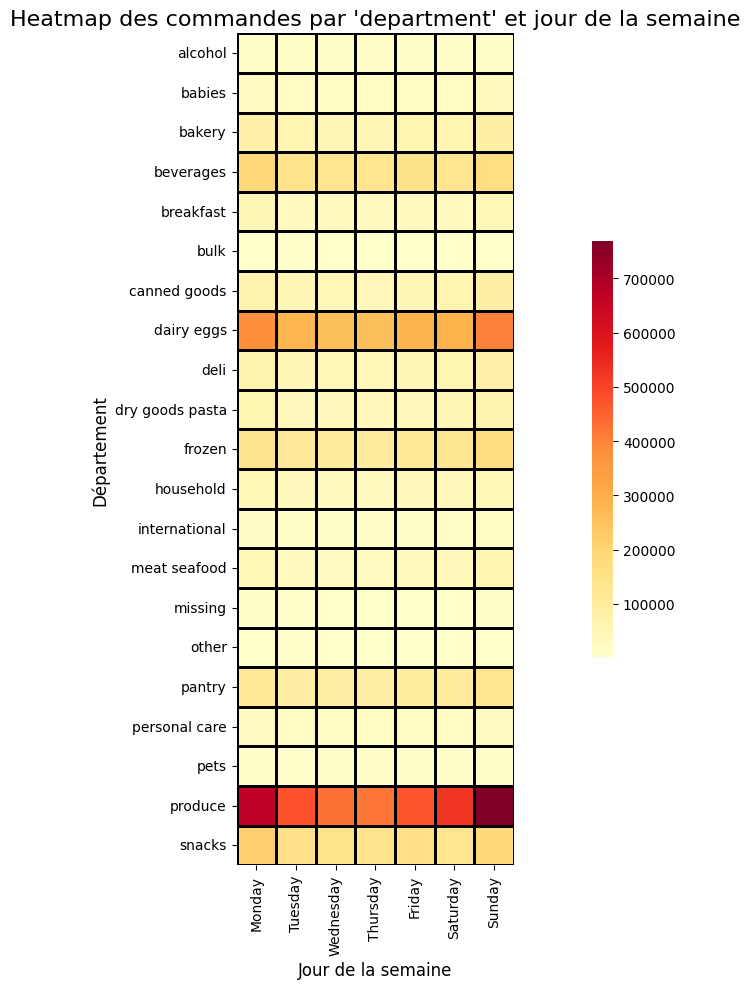

In [6]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")

days = {0: 'Sunday', 1: 'Monday', 2:'Tuesday', 3: 'Wednesday', 4:'Thursday', 5: 'Friday', 6:'Saturday'}
df['Jours'] = df['order_dow'].map(days)
order_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(16, 10)) 
heatmap= df.pivot_table(index='department' , columns='Jours' , aggfunc='size')
heatmap = heatmap[order_days]

sns.heatmap(heatmap, cmap='YlOrRd',  linewidths=1,linecolor='black',square=True, cbar_kws={'shrink': 0.5})

plt.title("Heatmap des commandes par 'department' et jour de la semaine", fontsize=16)
plt.ylabel("Département", fontsize=12)
plt.xlabel("Jour de la semaine", fontsize=12)
plt.tight_layout() 
plt.show()

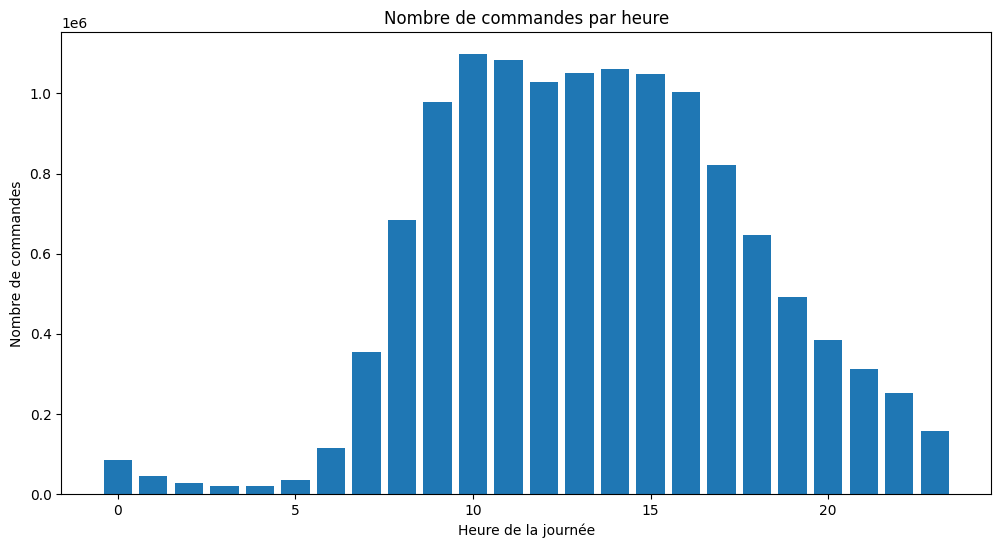

In [7]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")

CommandeParHeure = df['order_hour_of_day'].value_counts().sort_index()

plt.figure(figsize=(12,6))
plt.bar(CommandeParHeure.index, CommandeParHeure.values)

plt.title("Nombre de commandes par heure")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de commandes")


plt.show()

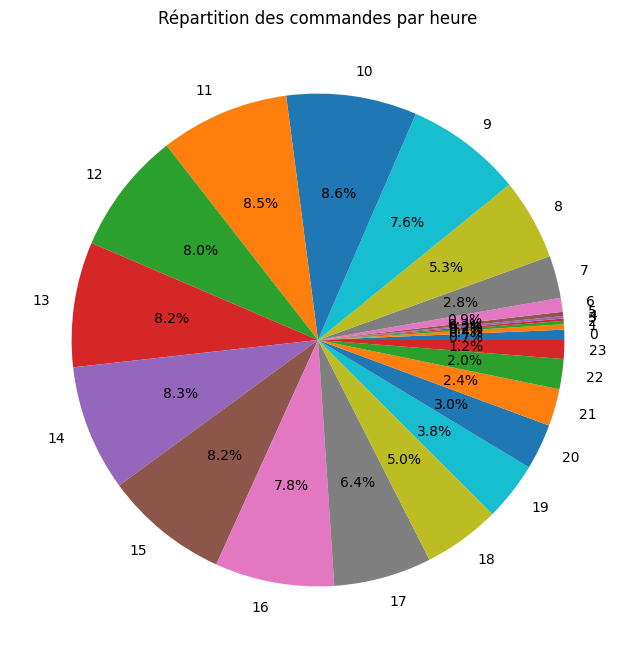

order_hour_of_day
0       85708
1       45569
2       27418
3       19692
4       20897
5       35114
6      116561
7      355950
8      683694
9      979247
10    1097700
11    1084210
12    1029646
13    1051397
14    1060845
15    1047269
16    1002789
17     822186
18     645873
19     492385
20     384379
21     312531
22     252789
23     157831
Name: count, dtype: int64


In [8]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")


CommandeParHeure = df['order_hour_of_day'].value_counts().sort_index()

plt.figure(figsize=(8,8))
plt.pie(CommandeParHeure, labels=CommandeParHeure.index, autopct='%1.1f%%') # label affiche de 0 à 23 les heures
plt.title("Répartition des commandes par heure")
plt.show()

print(CommandeParHeure)

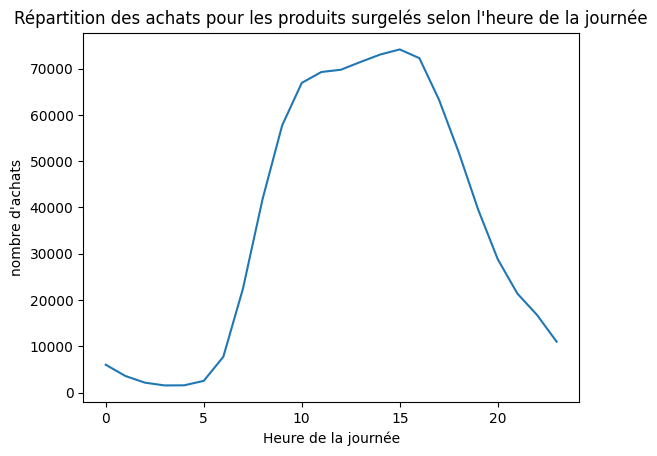

In [9]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")


df_top = df[df["department"] == "frozen"]

AchatParHeure = df_top["order_hour_of_day"].value_counts().sort_index() #value_count compte combien de fois chaque valeur apparaît dans la colonne  et sort_index
plt.plot(AchatParHeure.index, AchatParHeure.values) # 0.0  6578 exemple de ce qu'il y a dans AchatParHeure .index = 0.0 .values = 6578
plt.title("Répartition des achats pour les produits surgelés selon l'heure de la journée")
plt.ylabel('nombre d\'achats')
plt.xlabel('Heure de la journée')
plt.show()

## 7. Certains articles sont-ils recommandés plus d'une fois ?

## 8. Existe-t-il une corrélation entre le premier et le deuxième article acheté ?

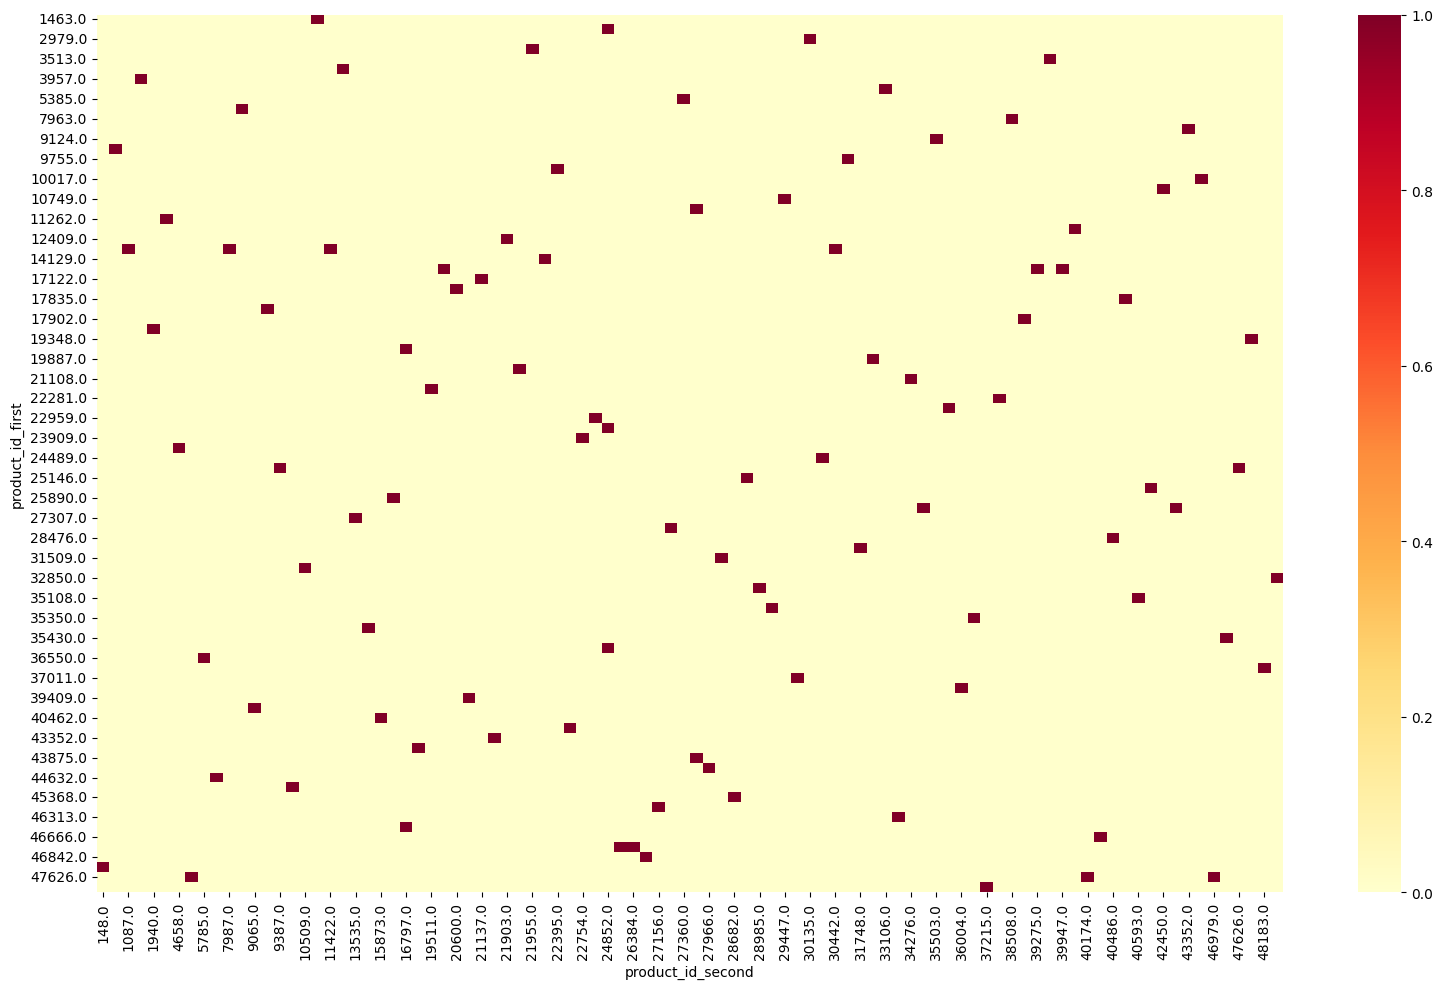

In [ ]:
df2 = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")
df4 = df2.head(1000)
first_article = df4[df4["add_to_cart_order"] == 1][["order_id", "product_id"]]
Second_article = df4[df4["add_to_cart_order"] == 2][["order_id", "product_id"]]

df3 = pd.merge(first_article,Second_article, on="order_id", suffixes=("_first", "_second"))

heatmap= df3.pivot_table(index="product_id_first" , columns="product_id_second" , aggfunc='size',fill_value=0)

plt.figure(figsize=(16,10))
sns.heatmap(heatmap, cmap="YlOrRd")
plt.title("Produits racheté après un autre produit")
plt.tight_layout() 
plt.show()

## 9. Pour quels jour et heure la catégorie alcool comporte le plus de vente ?

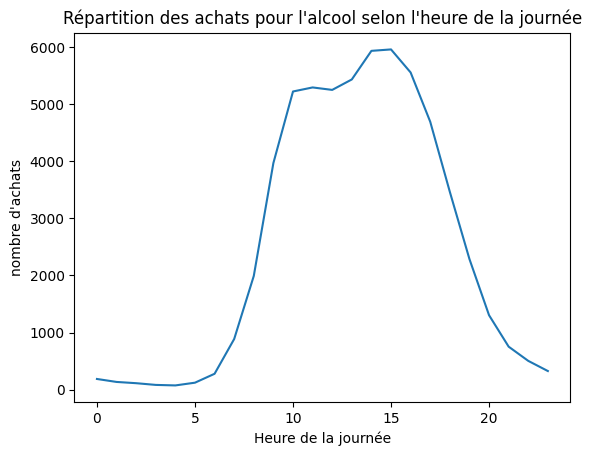

In [11]:
df = pd.read_csv("datasets-cleaned/df_order_products_clean.csv")


df_top = df[df["department"] == "alcohol"]

AchatParHeure = df_top["order_hour_of_day"].value_counts().sort_index()

plt.plot(AchatParHeure.index, AchatParHeure.values)
plt.title("Répartition des achats pour l'alcool selon l'heure de la journée")
plt.ylabel('nombre d\'achats')
plt.xlabel('Heure de la journée')
plt.show()

## 10. Peut-on prédire la taille d'un panier pour un client achetant de l'alcool ?

## 11. Parmi la catégorie "bakery", est-ce que les clients achètent plus de pain ("bread") le matin que de dessert ("bakery desserts") le midi et le soir ?